In [1]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

In [15]:
import matplotlib.pyplot as plt

In [4]:
pct = pd.read_csv('D:\\Research\\Political_Bias_of_LLMs\\diagonal_projection_analysis\\pct_model_summary_statistics.csv')

# sort by col 'model_name' -> lexicographically
pct = pct.sort_values(by=['model_name'])
pct.head()

,model_name,score_mean,score_SD,score_MAD
6,anthropic_claude_4_sonnet,-1.5264,0.0000,0.0000
25,cohere_command_r_08_2024,-0.4733,0.2200,0.1576
9,deepseek_ai_deepseek_v3,-1.3623,0.0000,0.0000
3,google_gemini_2_5_flash,-1.7548,0.2361,0.1691
0,google_gemini_2_5_pro,-2.1576,0.2342,0.1774


In [5]:
sapply = pd.read_csv('D:\\Research\\Political_Bias_of_LLMs\\diagonal_projection_analysis\\sapply_model_summary_statistics.csv')

# sort by col 'model_name' -> lexicographically
sapply = sapply.sort_values(by=['model_name'])
sapply.head()

,model_name,score_mean,score_SD,score_MAD
15,anthropic_claude_4_sonnet,-0.6780,0.0380,0.0289
8,cohere_command_r_08_2024,-0.8496,0.1163,0.0843
12,deepseek_ai_deepseek_v3,-0.7605,0.0319,0.0280
3,google_gemini_2_5_flash,-1.0558,0.0894,0.0641
1,google_gemini_2_5_pro,-1.1939,0.1132,0.0915


In [6]:
eightvalues = pd.read_csv('D:\\Research\\Political_Bias_of_LLMs\\diagonal_projection_analysis\\eightValues_model_summary_statistics.csv')

# sort by col 'model_name' -> lexicographically
eightvalues = eightvalues.sort_values(by=['model_name'])
eightvalues.head()

,model_name,score_mean,score_SD,score_MAD
19,anthropic_claude_4_sonnet,-0.6850,0.0396,0.0268
24,cohere_command_r_08_2024,-0.4827,0.0954,0.0694
15,deepseek_ai_deepseek_v3,-0.8043,0.0233,0.0216
0,google_gemini_2_5_flash,-1.0761,0.0572,0.0416
17,google_gemini_2_5_pro,-0.7627,0.1040,0.0785


In [7]:
# Merge the three dataframes on model_name, ensuring all models are present in all datasets
merged_df = pct[['model_name', 'score_mean']].rename(columns={'score_mean': 'pct_mean'})
merged_df = merged_df.merge(eightvalues[['model_name', 'score_mean']].rename(columns={'score_mean': 'eightvalues_mean'}), on='model_name', how='inner')
merged_df = merged_df.merge(sapply[['model_name', 'score_mean']].rename(columns={'score_mean': 'sapply_mean'}), on='model_name', how='inner')

# Display the merged dataframe
print(f"Number of models after merge: {len(merged_df)}")
merged_df.head()

Number of models after merge: 27


,model_name,pct_mean,eightvalues_mean,sapply_mean
0,anthropic_claude_4_sonnet,-1.5264,-0.6850,-0.6780
1,cohere_command_r_08_2024,-0.4733,-0.4827,-0.8496
2,deepseek_ai_deepseek_v3,-1.3623,-0.8043,-0.7605
3,google_gemini_2_5_flash,-1.7548,-1.0761,-1.0558
4,google_gemini_2_5_pro,-2.1576,-0.7627,-1.1939


In [8]:
# now add a col to merged_df named 'score' which is the average of pct_mean, eightvalues_mean, sapply_mean
merged_df['score'] = merged_df[['pct_mean', 'eightvalues_mean', 'sapply_mean']].mean(axis=1)
merged_df.head()

,model_name,pct_mean,eightvalues_mean,sapply_mean,score
0,anthropic_claude_4_sonnet,-1.5264,-0.6850,-0.6780,-0.963133
1,cohere_command_r_08_2024,-0.4733,-0.4827,-0.8496,-0.601867
2,deepseek_ai_deepseek_v3,-1.3623,-0.8043,-0.7605,-0.975700
3,google_gemini_2_5_flash,-1.7548,-1.0761,-1.0558,-1.295567
4,google_gemini_2_5_pro,-2.1576,-0.7627,-1.1939,-1.371400


In [9]:
# Calculate Spearman rank correlations
corr_pct_score, pval_pct_score = spearmanr(merged_df['pct_mean'], merged_df['score'])
corr_eightvalues_score, pval_eightvalues_score = spearmanr(merged_df['eightvalues_mean'], merged_df['score'])
corr_sapply_score, pval_sapply_score = spearmanr(merged_df['sapply_mean'], merged_df['score'])

print(f"Spearman correlation between pct_mean and score: {corr_pct_score:.4f}, p-value: {pval_pct_score:.4f}")
print(f"Spearman correlation between eightvalues_mean and score: {corr_eightvalues_score:.4f}, p-value: {pval_eightvalues_score:.4f}")
print(f"Spearman correlation between sapply_mean and score: {corr_sapply_score:.4f}, p-value: {pval_sapply_score:.4f}")

Spearman correlation between pct_mean and score: 0.8877, p-value: 0.0000
Spearman correlation between eightvalues_mean and score: 0.7814, p-value: 0.0000
Spearman correlation between sapply_mean and score: 0.7173, p-value: 0.0000


In [10]:
merged_df.to_csv('combine.csv', index=False)

In [14]:
merged_df = pd.read_csv('combine.csv')
merged_df.head()

,model_name,pct_mean,eightvalues_mean,sapply_mean,score
0,anthropic_claude_4_sonnet,-1.5264,-0.6850,-0.6780,-0.963133
1,cohere_command_r_08_2024,-0.4733,-0.4827,-0.8496,-0.601867
2,deepseekAi_deepseek_v3,-1.3623,-0.8043,-0.7605,-0.975700
3,google_gemini_2_5_flash,-1.7548,-1.0761,-1.0558,-1.295567
4,google_gemini_2_5_pro,-2.1576,-0.7627,-1.1939,-1.371400


C:\Users\sakha\AppData\Local\Temp\ipykernel_22680\1064623032.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('tab20', num_providers)


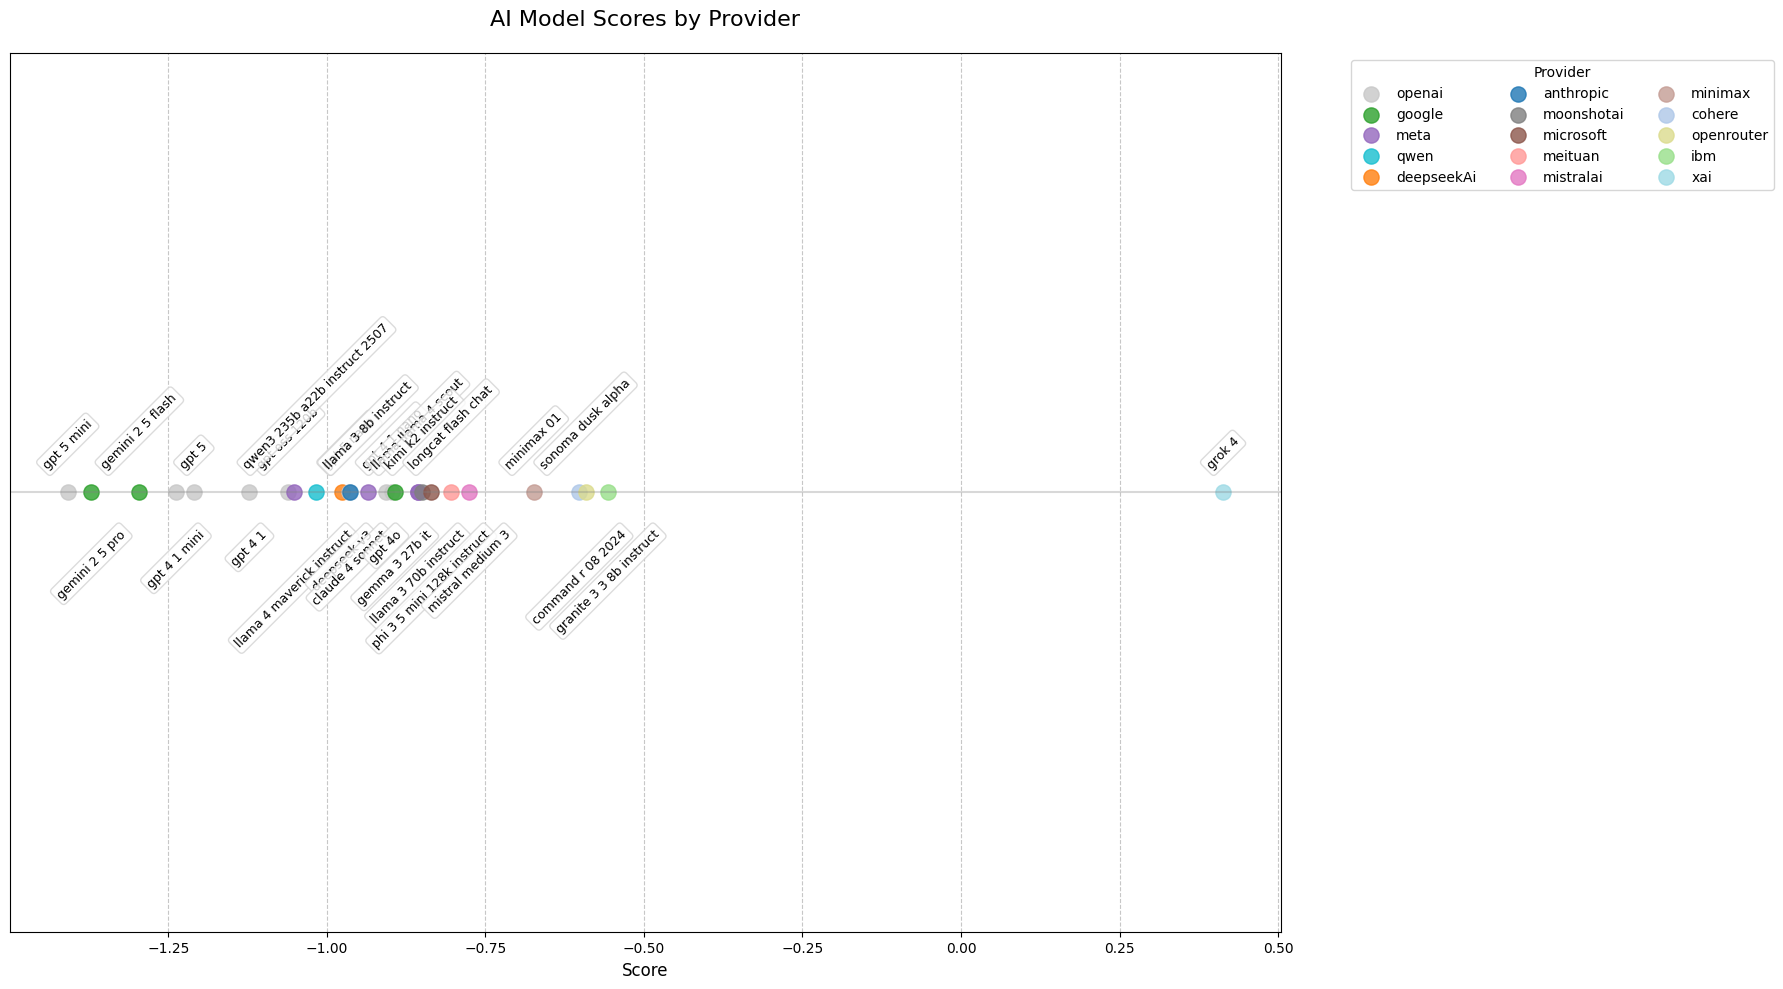


Spearman correlation between pct_mean and score: 0.8877, p-value: 0.0000
Spearman correlation between eightvalues_mean and score: 0.7814, p-value: 0.0000
Spearman correlation between sapply_mean and score: 0.7173, p-value: 0.0000

Provider Statistics:
Number of unique providers: 15
Providers found: anthropic, cohere, deepseekAi, google, ibm, meituan, meta, microsoft, minimax, mistralai, moonshotai, openai, openrouter, qwen, xai


In [16]:
# Extract provider names from model_name
merged_df['provider'] = merged_df['model_name'].apply(lambda x: x.split('_')[0])

# Get unique providers and create a consistent color mapping
unique_providers = merged_df['provider'].unique()
num_providers = len(unique_providers)

# Use a colormap that generates distinct colors for any number of providers
# Using 'tab20' colormap which has 20 distinct colors - good for many providers
colormap = plt.cm.get_cmap('tab20', num_providers)
provider_colors = {provider: colormap(i) for i, provider in enumerate(unique_providers)}

# Sort by score for better visualization
merged_df = merged_df.sort_values('score')

# Create figure with wide aspect ratio
plt.figure(figsize=(18, 10))

# Plot each model with provider-specific color
for idx, (i, row) in enumerate(merged_df.iterrows()):
    provider = row['provider']
    color = provider_colors[provider]
    
    # Plot the point
    plt.scatter(row['score'], 0, color=color, s=120, alpha=0.8, 
                label=provider if provider not in plt.gca().get_legend_handles_labels()[1] else "")
    
    # Add model name label with smart positioning
    offset_direction = 15 if idx % 2 == 0 else -25
    plt.annotate(row['model_name'].split('_', 1)[1].replace('_', ' '), 
                (row['score'], 0), 
                xytext=(0, offset_direction), 
                textcoords='offset points', 
                ha='center', 
                va='bottom' if offset_direction > 0 else 'top',
                fontsize=9,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='lightgray'),
                rotation=45)

# Add a horizontal line at y=0 for reference
plt.axhline(y=0, color='gray', linestyle='-', alpha=0.3)

# Customize the plot
plt.title('AI Model Scores by Provider', fontsize=16, pad=20)
plt.xlabel('Score', fontsize=12)
plt.ylabel('')
plt.yticks([])  # Remove y-axis ticks
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add legend for providers with dynamic positioning
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))  # Remove duplicates

# Adjust legend position based on number of providers
legend_cols = min(3, (num_providers + 4) // 5)  # Dynamic column calculation
plt.legend(by_label.values(), by_label.keys(), 
           title='Provider', 
           bbox_to_anchor=(1.05, 1), 
           loc='upper left',
           ncol=legend_cols)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

# Calculate Spearman rank correlations with error handling
def safe_spearmanr(x, y, col_name):
    try:
        correlation, p_value = spearmanr(x, y)
        return correlation, p_value
    except Exception as e:
        print(f"Error calculating Spearman correlation for {col_name}: {e}")
        return np.nan, np.nan

corr_pct_score, pval_pct_score = safe_spearmanr(merged_df['pct_mean'], merged_df['score'], 'pct_mean')
corr_eightvalues_score, pval_eightvalues_score = safe_spearmanr(merged_df['eightvalues_mean'], merged_df['score'], 'eightvalues_mean')
corr_sapply_score, pval_sapply_score = safe_spearmanr(merged_df['sapply_mean'], merged_df['score'], 'sapply_mean')

print(f"\nSpearman correlation between pct_mean and score: {corr_pct_score:.4f}, p-value: {pval_pct_score:.4f}")
print(f"Spearman correlation between eightvalues_mean and score: {corr_eightvalues_score:.4f}, p-value: {pval_eightvalues_score:.4f}")
print(f"Spearman correlation between sapply_mean and score: {corr_sapply_score:.4f}, p-value: {pval_sapply_score:.4f}")

# Additional analysis: Show provider statistics
print(f"\nProvider Statistics:")
print(f"Number of unique providers: {num_providers}")
print("Providers found:", ", ".join(sorted(unique_providers)))